# Klassifisering av overlevelse på Titanic med k-nærmeste nabo (KNN)

**Problemstilling (definert før vi så resultatene):**

Jeg ønsker å forsøke å klassifisere om en passasjer overlevde eller ikke.
1. Først sjekker jeg basert på kjønn og alder.
2. Så sjekker jeg om status (klasse) har en påvirkning.
3. Til slutt sjekker jeg om antall familiemedlemmer om bord har noe å si.

## Importer

In [4]:
import pandas as pd                                   # datahåndtering (tabeller)
import numpy as np                                    # tallrekker og numeriske operasjoner
import matplotlib.pyplot as plt                       # plotting
from sklearn.model_selection import train_test_split  # deling i trening/validering/test
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier    # KNN-klassifikatoren
from sklearn.preprocessing import StandardScaler      # standardisering av forklaringsvariabler

## Last inn data

In [5]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Forbehandling av data

- `FamilySize = SibSp + Parch` (søsken/ektefelle + foreldre/barn). Passasjeren selv er ikke talt med.
- KNN regner avstander, så alle forklaringsvariabler må være tall. `Sex` gjøres om til 0/1 (male = 0, female = 1).

In [6]:
df["FamilySize"] = df["SibSp"] + df["Parch"]
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

## Deling av data

60 % trening, 20 % validering, 20 % testing.

- Steg 1: 60 % trening / 40 % «temp». Steg 2: temp deles 50/50 → 20 % validering og 20 % test.
- `stratify=...` gir lik andel `Survived` i alle tre sett (viktig siden klassene er skjevfordelt).
- `random_state=1` gjør delingen reproduserbar.

Treningssettet brukes til å tilpasse modellen, valideringssettet til å velge modell og k, og testsettet brukes **kun** til slutt for et ærlig estimat av ytelsen.

In [7]:
df_trening, temp = train_test_split(df, test_size=0.4, random_state=1, stratify=df["Survived"])
df_val, df_test = train_test_split(temp, test_size=0.5, random_state=1, stratify=temp["Survived"])

## Definisjon av modellene

Tre modeller med gradvis flere forklaringsvariabler (hver bygger på den forrige), slik at vi kan se om hver ekstra variabel forbedrer prediksjonen.

Alle modellene evalueres på samme valideringsrader, slik at de er sammenlignbare. Vi bruker alle kolonner fra modell 3 og fjerner rader med manglende verdi (hovedsakelig `Age`).

In [8]:
modeller_def = {
    "Modell 1: Sex + Age": ['Sex', 'Age'],
    "Modell 2: + Pclass": ['Sex', 'Age', 'Pclass'],
    "Modell 3: + FamilySize": ['Sex', 'Age', 'Pclass', 'FamilySize'],
}

alle_kolonner = ['Survived', 'Sex', 'Age', 'Pclass', 'FamilySize']
df_val_clean = df_val[alle_kolonner].dropna()
y_val = df_val_clean['Survived']

# Verdier av k vi prøver (kun odde tall, slik at vi unngår uavgjort i flertallsavstemningen)
knaboer = np.arange(1, 199, step=2)

# Beholdere for resultater
resultater = {}        # beste k og tilhørende valideringsfeilrate per modell
val_feilrater = {}     # hele feilrate-kurven (mot k) per modell, brukes til plotting
beste_modeller = {}    # lagrer scaler, beste k, kolonner og treningsdata per modell

## Tilpasning og valg av k for hver modell

Variablene standardiseres slik at `Age` (0–80) ikke dominerer avstanden over `Sex` (0/1). Skaleringen læres kun fra treningsdata (`fit_transform`), og valideringsdata skaleres med samme parametre (`transform`) for å unngå data leakage.

In [9]:
for navn, x_kolonner in modeller_def.items():
    # Treningsdata (fjern rader med manglende verdier)
    df_tren = df_trening[['Survived'] + x_kolonner].dropna()

    scaler = StandardScaler()
    X_tren = scaler.fit_transform(df_tren[x_kolonner])
    X_val = scaler.transform(df_val_clean[x_kolonner])
    y_tren = df_tren['Survived']

    # Feilrate på valideringssettet for hver k
    val_feilrate = np.empty(len(knaboer))
    for i, k in enumerate(knaboer):
        # p=2 betyr euklidsk avstand
        knn = KNeighborsClassifier(n_neighbors=k, p=2)
        knn.fit(X_tren, y_tren)
        # score() gir andel riktige, så feilrate = 1 - score
        val_feilrate[i] = 1 - knn.score(X_val, y_val)

    val_feilrater[navn] = val_feilrate

    # Velg k med lavest feilrate på valideringssettet
    i_beste = np.argmin(val_feilrate)
    beste_modeller[navn] = (scaler, knaboer[i_beste], x_kolonner, df_tren)
    resultater[navn] = {
        "Beste k": knaboer[i_beste],
        "Feilrate (val)": val_feilrate[i_beste],
    }

## Baseline og oppsummering

Baseline: alltid gjette den vanligste klassen. Modellene våre må slå denne for å være nyttige.

In [10]:
baseline = 1 - y_val.value_counts(normalize=True).max()

print(pd.DataFrame(resultater).T)
print("Baseline feilrate:", baseline)

                        Beste k  Feilrate (val)
Modell 1: Sex + Age        31.0        0.225352
Modell 2: + Pclass        103.0        0.190141
Modell 3: + FamilySize     95.0        0.183099
Baseline feilrate: 0.4014084507042254


## Plot: feilrate mot k for hver modell

Viser hvordan fleksibiliteten (liten k = fleksibel, stor k = stiv) påvirker feilraten.

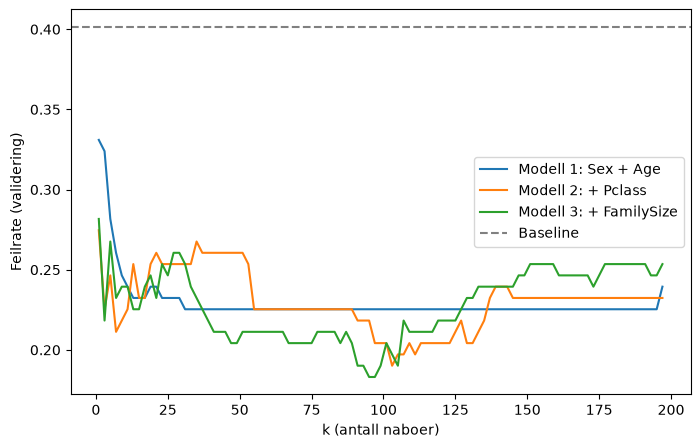

In [11]:
plt.figure(figsize=(8, 5))
for navn, feilrate in val_feilrater.items():
    plt.plot(knaboer, feilrate, label=navn)
plt.axhline(baseline, color="gray", linestyle="--", label="Baseline")
plt.xlabel("k (antall naboer)")
plt.ylabel("Feilrate (validering)")
plt.legend()
plt.show()

## Endelig modellvalg

In [12]:
# 1. Velg beste modell: lavest feilrate på valideringssettet
resultater_df = pd.DataFrame(resultater).T
beste_navn = resultater_df["Feilrate (val)"].idxmin()
scaler, beste_k, x_kolonner, df_tren = beste_modeller[beste_navn]

print("Beste modell:", beste_navn)
print("Beste k:", beste_k)
print("Feilrate (val):", resultater_df.loc[beste_navn, "Feilrate (val)"])

# 2. Tren endelig modell på treningsdata med beste k
# (scaleren er den som ble tilpasset treningsdata for akkurat denne modellen)
X_tren = scaler.transform(df_tren[x_kolonner])
y_tren = df_tren['Survived']

knn_best = KNeighborsClassifier(n_neighbors=int(beste_k), p=2)
knn_best.fit(X_tren, y_tren)

Beste modell: Modell 3: + FamilySize
Beste k: 95
Feilrate (val): 0.18309859154929575


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",95
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Evaluering på testsettet

Testsettet brukes kun én gang.

In [13]:
# 3. Predikasjon på testsettet (fjern rader med manglende verdier, bruk samme skalering)
df_test_clean = df_test[['Survived'] + x_kolonner].dropna()
X_test = scaler.transform(df_test_clean[x_kolonner])
y_test = df_test_clean['Survived']

y_testpred = knn_best.predict(X_test)

# Feilrate på testsett og tilhørende baseline, for et ærlig estimat på ukjente data
test_feilrate = 1 - accuracy_score(y_true=y_test, y_pred=y_testpred)
baseline_test = 1 - y_test.value_counts(normalize=True).max()

print("Feilrate (test):", test_feilrate)
print("Baseline feilrate (test):", baseline_test)

Feilrate (test): 0.2027972027972028
Baseline feilrate (test): 0.43356643356643354


## Forvekslingsmatrise

Rader = faktisk, kolonner = predikert. Nyttig for å se sensitivitet og spesifisitet.

In [14]:
cm = confusion_matrix(y_test, y_testpred)

print(pd.DataFrame(
    cm,
    index=["Faktisk: døde", "Faktisk: overlevde"],
    columns=["Pred: døde", "Pred: overlevde"],
))

                    Pred: døde  Pred: overlevde
Faktisk: døde               72                9
Faktisk: overlevde          20               42


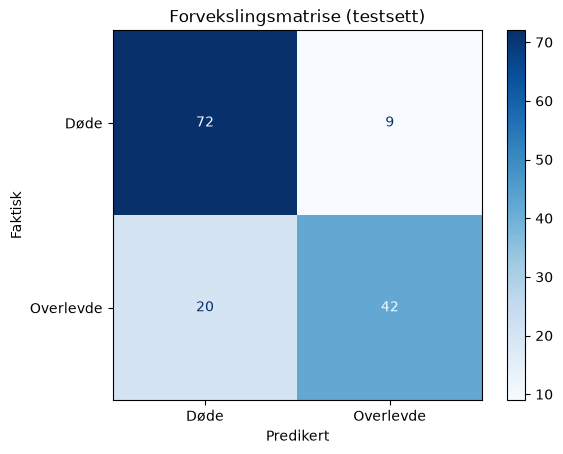

In [15]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Døde", "Overlevde"],
)
disp.plot(cmap="Blues")
plt.title("Forvekslingsmatrise (testsett)")
plt.xlabel("Predikert")
plt.ylabel("Faktisk")
plt.show()